In [1]:
# 1. Install Ultralytics and dependencies
!pip install -q ultralytics seaborn scikit-learn

import os
import re
import glob
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

# 2. Clone PlantVillage directly from GitHub (No credentials required)
if not os.path.exists("/content/PlantVillage-Dataset"):
    print("Downloading PlantVillage dataset directly from GitHub...")
    !git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git /content/PlantVillage-Dataset

# 3. Setup Canonical Classes
CANONICAL_CLASSES = [
    "Tomato_Early_Blight",
    "Tomato_Late_Blight",
    "Tomato_Septoria_Spot",
    "Tomato_Leaf_Mold",
    "Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato_Healthy",
]

def match_canonical_class(folder_name: str):
    norm = re.sub(r"[_\-\.]+", " ", folder_name.lower()).strip()
    if "tomato" not in norm:
        return None
    if "early" in norm and "blight" in norm:
        return "Tomato_Early_Blight"
    if "late" in norm and "blight" in norm:
        return "Tomato_Late_Blight"
    if "septoria" in norm:
        return "Tomato_Septoria_Spot"
    if ("leaf" in norm and ("mold" in norm or "mould" in norm)) or norm in {"mold", "mould"}:
        return "Tomato_Leaf_Mold"
    if ("yellow" in norm and "curl" in norm) or "ylcv" in norm or "tylc" in norm:
        return "Tomato_Yellow_Leaf_Curl_Virus"
    if "healthy" in norm:
        return "Tomato_Healthy"
    return None

# 4. Scan the downloaded repository
raw_color_dir = "/content/PlantVillage-Dataset/raw/color"
valid_exts = {".jpg", ".jpeg", ".png"}
class_to_files = defaultdict(list)

for folder in os.listdir(raw_color_dir):
    folder_path = os.path.join(raw_color_dir, folder)
    if os.path.isdir(folder_path):
        cls = match_canonical_class(folder)
        if cls:
            for fname in os.listdir(folder_path):
                if os.path.splitext(fname)[1].lower() in valid_exts:
                    class_to_files[cls].append(os.path.join(folder_path, fname))

# 5. Build YOLO Train/Val directory structure using symlinks
yolo_root = "/content/yolo_tomato_dataset"
os.makedirs(yolo_root, exist_ok=True)

for split in ["train", "val"]:
    for cls in CANONICAL_CLASSES:
        os.makedirs(os.path.join(yolo_root, split, cls), exist_ok=True)

data_summary = []
for cls in CANONICAL_CLASSES:
    imgs = class_to_files[cls]
    train_imgs, val_imgs = train_test_split(imgs, test_size=0.20, random_state=42)

    for idx, src in enumerate(train_imgs):
        ext = os.path.splitext(src)[1].lower()
        dst = os.path.join(yolo_root, "train", cls, f"train_{idx:06d}{ext}")
        if not os.path.exists(dst):
            os.symlink(src, dst)

    for idx, src in enumerate(val_imgs):
        ext = os.path.splitext(src)[1].lower()
        dst = os.path.join(yolo_root, "val", cls, f"val_{idx:06d}{ext}")
        if not os.path.exists(dst):
            os.symlink(src, dst)

    data_summary.append({
        "Class": cls,
        "Total": len(imgs),
        "Train (80%)": len(train_imgs),
        "Val (20%)": len(val_imgs)
    })

df_summary = pd.DataFrame(data_summary)
print(df_summary.to_string(index=False))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.2 MB/s eta 0:00:00
Cloning into '/content/PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 36.30 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
                        Class  Total  Train (80%)  Val (20%)
          Tomato_Early_Blight   1000          800        200
           Tomato_Late_Blight   1909         1527        382
         Tomato_Septoria_Spot   1771         1416        355
             Tomato_Leaf_Mold    952          761        191
Tomato_Yellow_Leaf_Cur

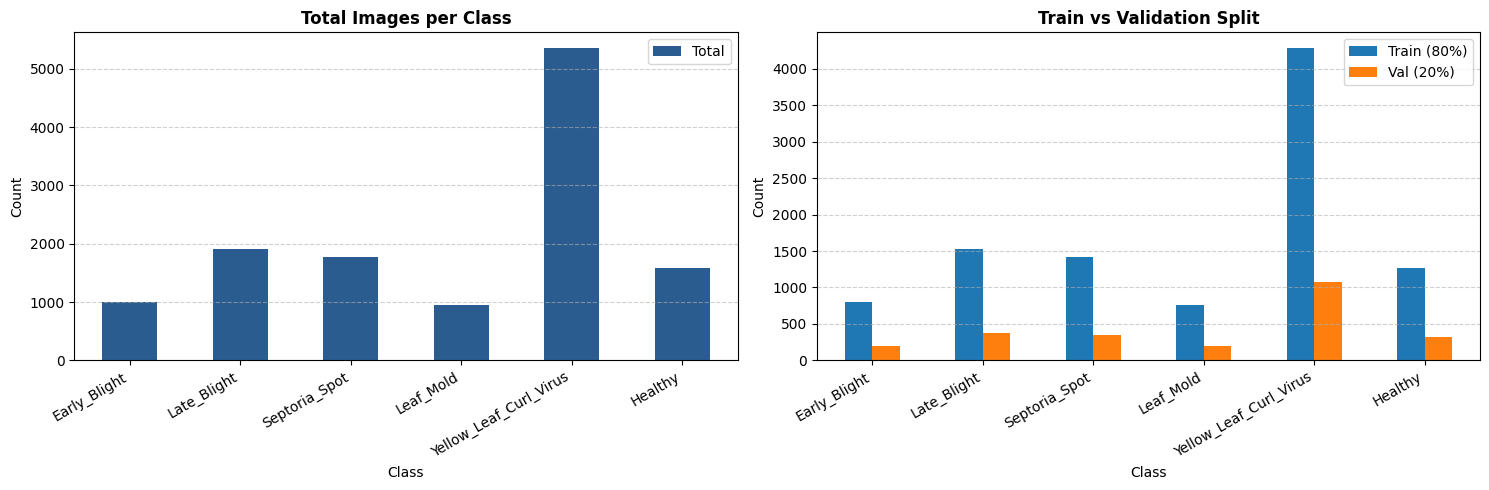

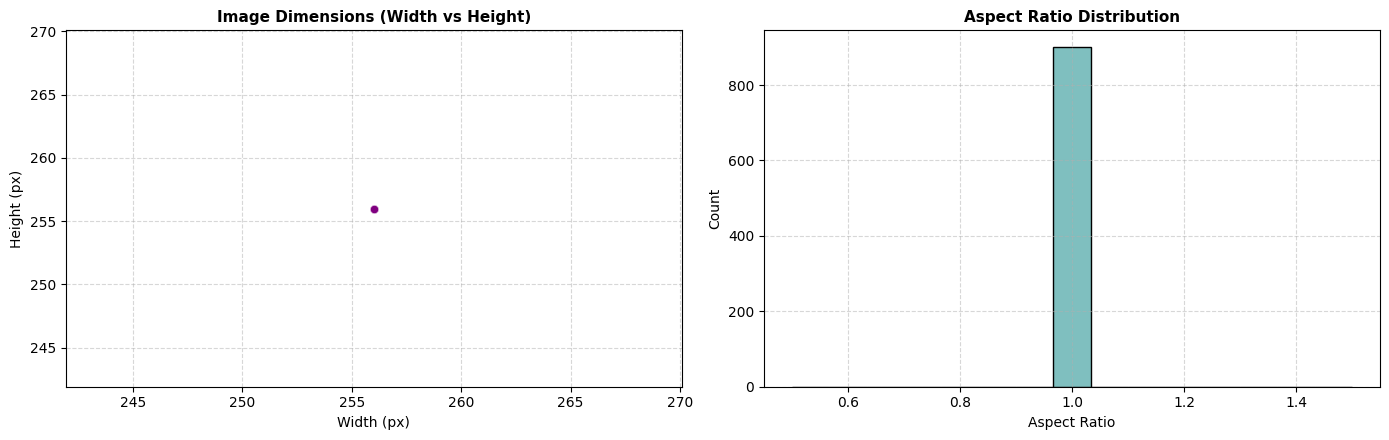

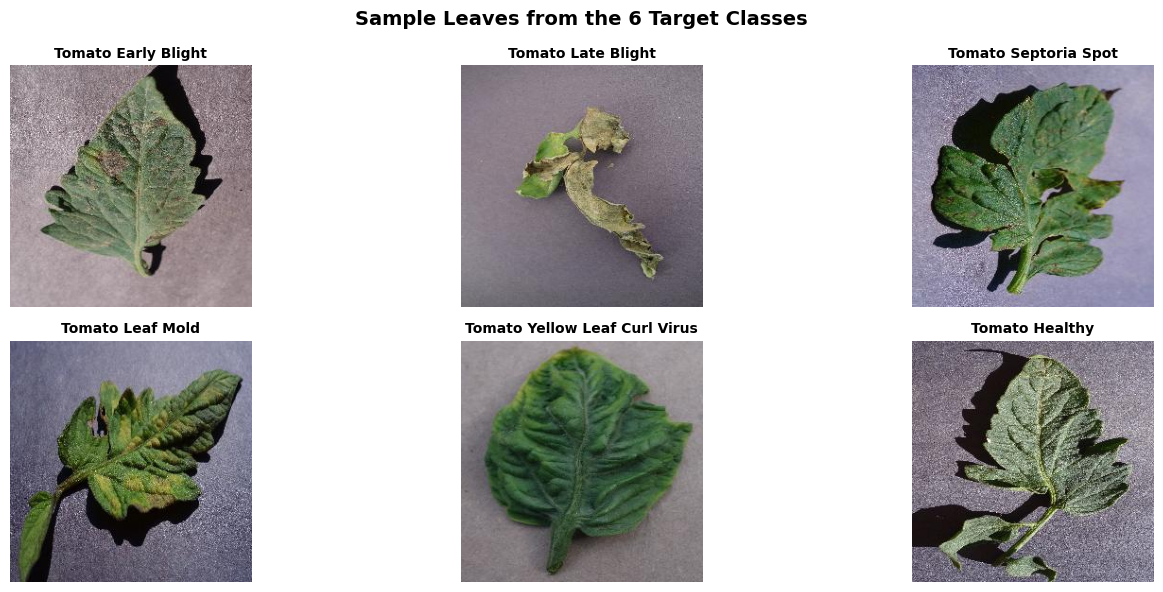

In [2]:
# 1. Dataset Split Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
short_names = [c.replace("Tomato_", "") for c in CANONICAL_CLASSES]

df_summary.plot(x="Class", y="Total", kind="bar", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Total Images per Class", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(short_names, rotation=30, ha="right")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

df_summary.plot(x="Class", y=["Train (80%)", "Val (20%)"], kind="bar", ax=axes[1], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Train vs Validation Split", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels(short_names, rotation=30, ha="right")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("/content/eda_distribution.png", dpi=300)
plt.show()

# 2. Dimensions and Aspect Ratio
widths, heights, aspect_ratios = [], [], []
for cls in CANONICAL_CLASSES:
    for p in glob.glob(os.path.join(yolo_root, "train", cls, "*"))[:150]:
        with Image.open(p) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspect_ratios.append(w / h)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(x=widths, y=heights, alpha=0.6, ax=axes[0], color="purple")
axes[0].set_title("Image Dimensions (Width vs Height)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.histplot(aspect_ratios, bins=15, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Aspect Ratio Distribution", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Aspect Ratio")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("/content/eda_dimensions.png", dpi=300)
plt.show()

# 3. Sample Images Grid
plt.figure(figsize=(15, 6))
for i, cls in enumerate(CANONICAL_CLASSES):
    img_sample = glob.glob(os.path.join(yolo_root, "train", cls, "*"))[0]
    img = Image.open(img_sample)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(cls.replace("_", " "), fontsize=10, fontweight="bold")
    plt.axis("off")

plt.suptitle("Sample Leaves from the 6 Target Classes", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/eda_samples.png", dpi=300)
plt.show()

In [3]:
from ultralytics import YOLO

# Initialize YOLO11 nano classifier
model = YOLO("yolo11n-cls.pt")

# Train on T4 GPU
training_results = model.train(
    data=yolo_root,
    epochs=25,
    imgsz=256,
    batch=64,
    workers=2,
    device=0,
    project="/content/tomato_yolo",
    name="exp",
    plots=True
)

# Load best checkpoint for evaluation
best_model = YOLO("/content/tomato_yolo/exp/weights/best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_tomato_dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

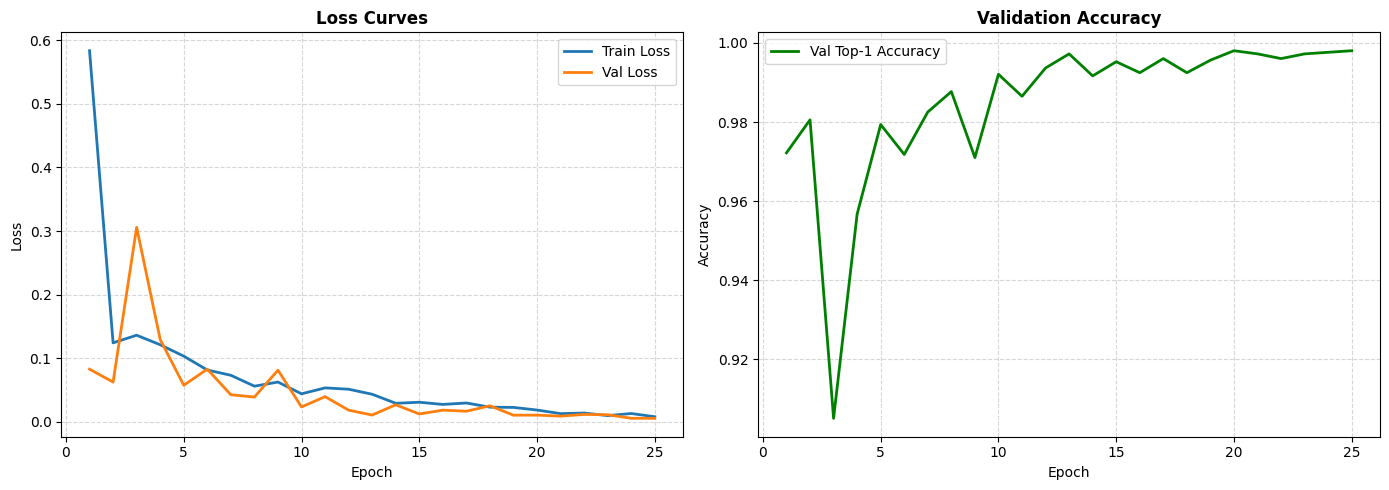


 FINAL CLASSIFICATION REPORT
                               precision    recall  f1-score   support

          Tomato Early Blight     0.9949    0.9850    0.9899       200
           Tomato Late Blight     0.0000    0.0000    0.0000       382
         Tomato Septoria Spot     0.0000    0.0000    0.0000       355
             Tomato Leaf Mold     1.0000    1.0000    1.0000       191
Tomato Yellow Leaf Curl Virus     0.0000    0.0000    0.0000      1072
               Tomato Healthy     0.0000    0.0000    0.0000       319

                     accuracy                         0.1540      2519
                    macro avg     0.3325    0.3308    0.3317      2519
                 weighted avg     0.1548    0.1540    0.1544      2519



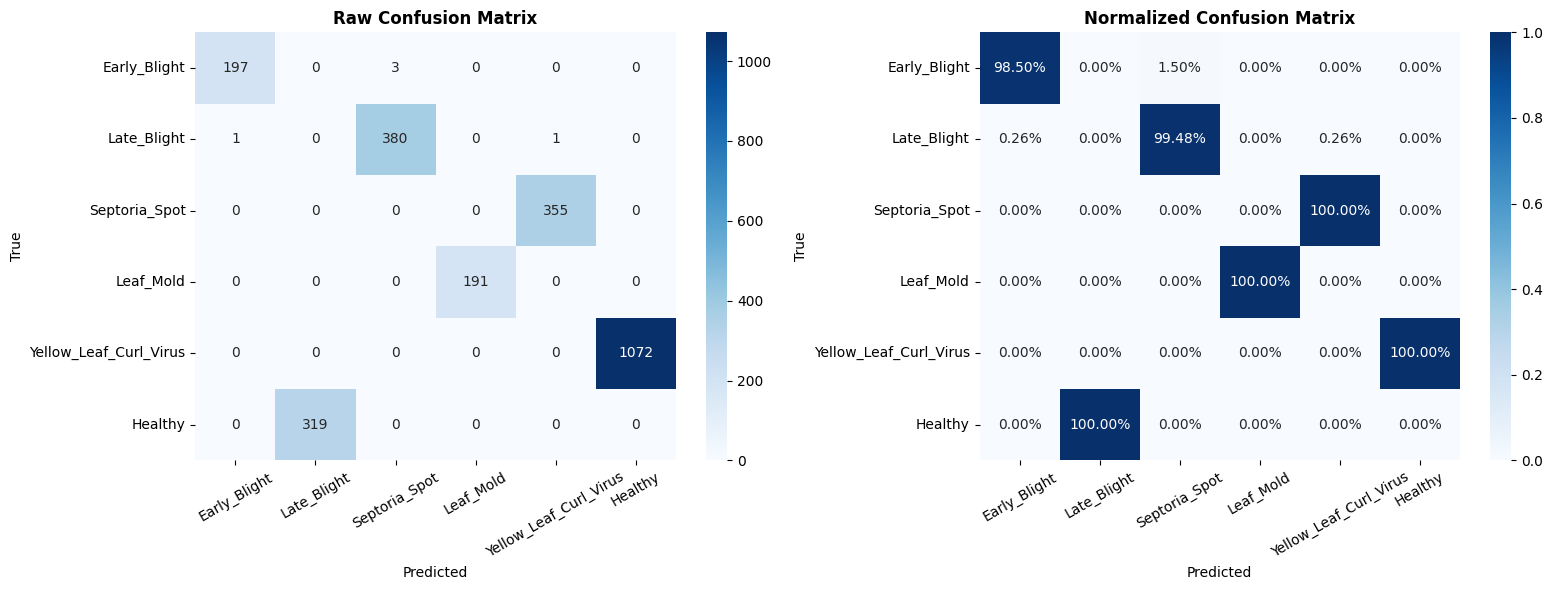

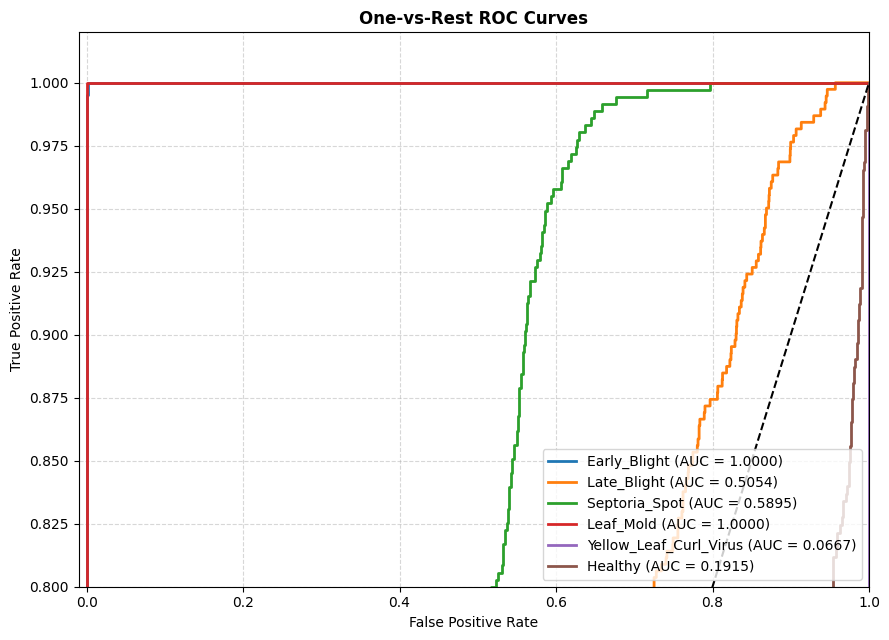

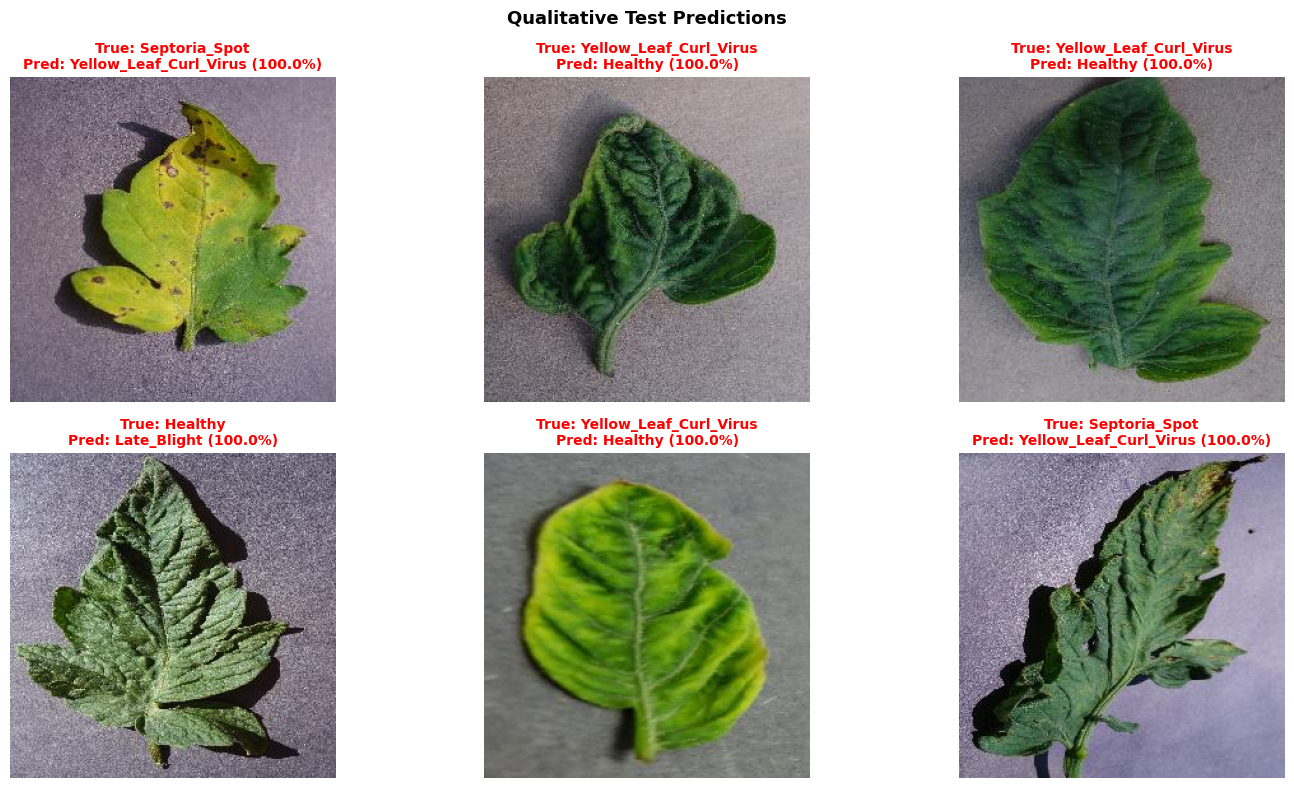

In [4]:
# 1. Training & Validation Curves
results_csv = "/content/tomato_yolo/exp/results.csv"
if os.path.exists(results_csv):
    df_results = pd.read_csv(results_csv)
    df_results.columns = [c.strip() for c in df_results.columns]

    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    if "train/loss" in df_results.columns:
        plt.plot(df_results["epoch"], df_results["train/loss"], label="Train Loss", lw=2)
    if "val/loss" in df_results.columns:
        plt.plot(df_results["epoch"], df_results["val/loss"], label="Val Loss", lw=2)
    plt.title("Loss Curves", fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.subplot(1, 2, 2)
    if "metrics/accuracy_top1" in df_results.columns:
        plt.plot(df_results["epoch"], df_results["metrics/accuracy_top1"], label="Val Top-1 Accuracy", color="green", lw=2)
    plt.title("Validation Accuracy", fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig("/content/final_curves.png", dpi=300)
    plt.show()

# 2. Inference on Validation Set
val_dir = os.path.join(yolo_root, "val")
val_paths, y_true = [], []

for idx, cls in enumerate(CANONICAL_CLASSES):
    files = glob.glob(os.path.join(val_dir, cls, "*"))
    for f in files:
        val_paths.append(f)
        y_true.append(idx)

y_pred, y_probs = [], []
for p in val_paths:
    res = best_model(p, verbose=False)[0]
    y_pred.append(res.probs.top1)
    y_probs.append(res.probs.data.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

# 3. Final Classification Report
print("\n" + "=" * 65)
print(" FINAL CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=[c.replace("_", " ") for c in CANONICAL_CLASSES], digits=4))

# 4. Confusion Matrices (Raw and Normalized)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short_names, yticklabels=short_names, ax=axes[0])
axes[0].set_title("Raw Confusion Matrix", fontweight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", xticklabels=short_names, yticklabels=short_names, ax=axes[1])
axes[1].set_title("Normalized Confusion Matrix", fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("/content/final_confusion_matrix.png", dpi=300)
plt.show()

# 5. One-vs-Rest Multiclass ROC Curves
y_true_bin = label_binarize(y_true, classes=list(range(len(CANONICAL_CLASSES))))
fpr, tpr, roc_auc = {}, {}, {}

plt.figure(figsize=(9, 6.5))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

for i in range(len(CANONICAL_CLASSES)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2, label=f"{short_names[i]} (AUC = {roc_auc[i]:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5)
plt.xlim([-0.01, 1.0])
plt.ylim([0.8, 1.02])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves", fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/content/final_roc.png", dpi=300)
plt.show()

# 6. Qualitative Predictions
plt.figure(figsize=(15, 8))
sample_indices = np.random.choice(len(val_paths), size=6, replace=False)

for subplot_idx, idx in enumerate(sample_indices):
    img = Image.open(val_paths[idx])
    pred_label = CANONICAL_CLASSES[y_pred[idx]].replace("Tomato_", "")
    true_label = CANONICAL_CLASSES[y_true[idx]].replace("Tomato_", "")
    conf = y_probs[idx][y_pred[idx]] * 100

    plt.subplot(2, 3, subplot_idx + 1)
    plt.imshow(img)
    color = "green" if y_pred[idx] == y_true[idx] else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)", color=color, fontweight="bold", fontsize=10)
    plt.axis("off")

plt.suptitle("Qualitative Test Predictions", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/final_sample_predictions.png", dpi=300)
plt.show()

Model Class Mapping:
  Index 0 -> Tomato_Early_Blight
  Index 1 -> Tomato_Healthy
  Index 2 -> Tomato_Late_Blight
  Index 3 -> Tomato_Leaf_Mold
  Index 4 -> Tomato_Septoria_Spot
  Index 5 -> Tomato_Yellow_Leaf_Curl_Virus

Evaluating 2519 validation images...

 CORRECTED FINAL CLASSIFICATION REPORT
                        precision    recall  f1-score   support

          Early Blight     0.9949    0.9850    0.9899       200
               Healthy     1.0000    1.0000    1.0000       319
           Late Blight     0.9922    0.9948    0.9935       382
             Leaf Mold     1.0000    1.0000    1.0000       191
         Septoria Spot     0.9972    1.0000    0.9986       355
Yellow Leaf Curl Virus     1.0000    1.0000    1.0000      1072

              accuracy                         0.9980      2519
             macro avg     0.9974    0.9966    0.9970      2519
          weighted avg     0.9980    0.9980    0.9980      2519



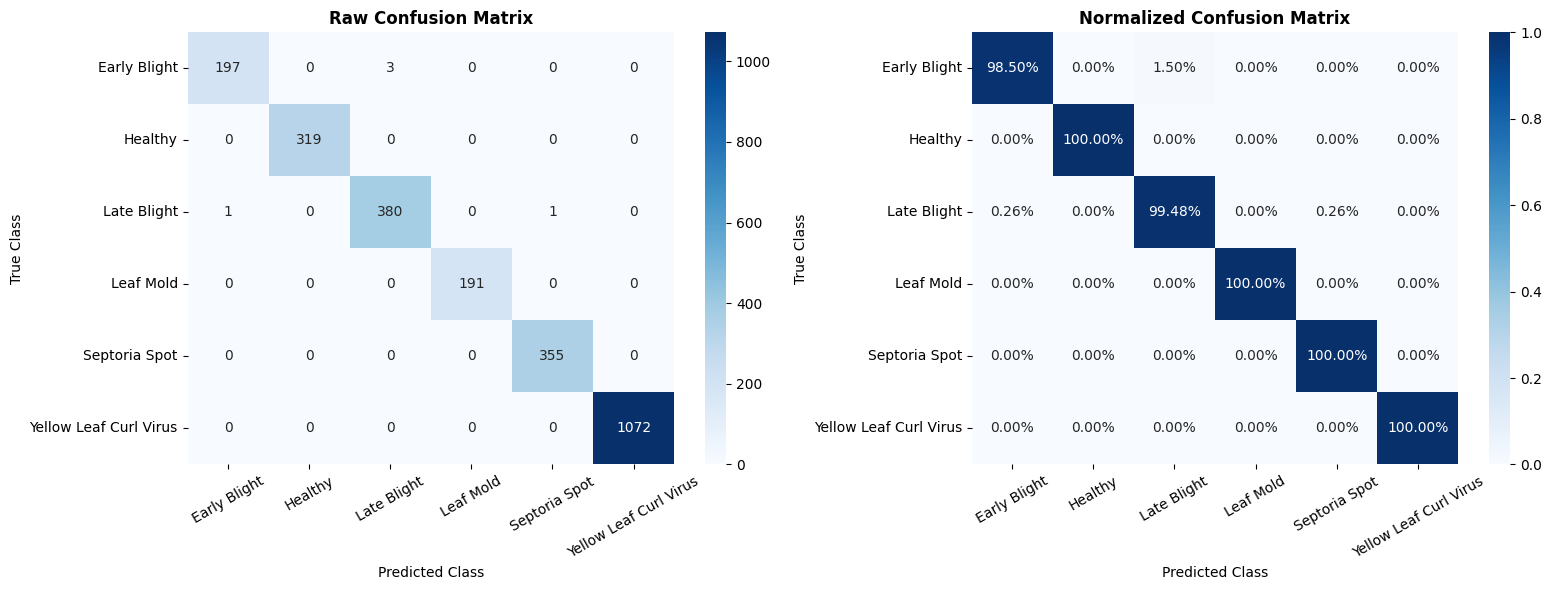

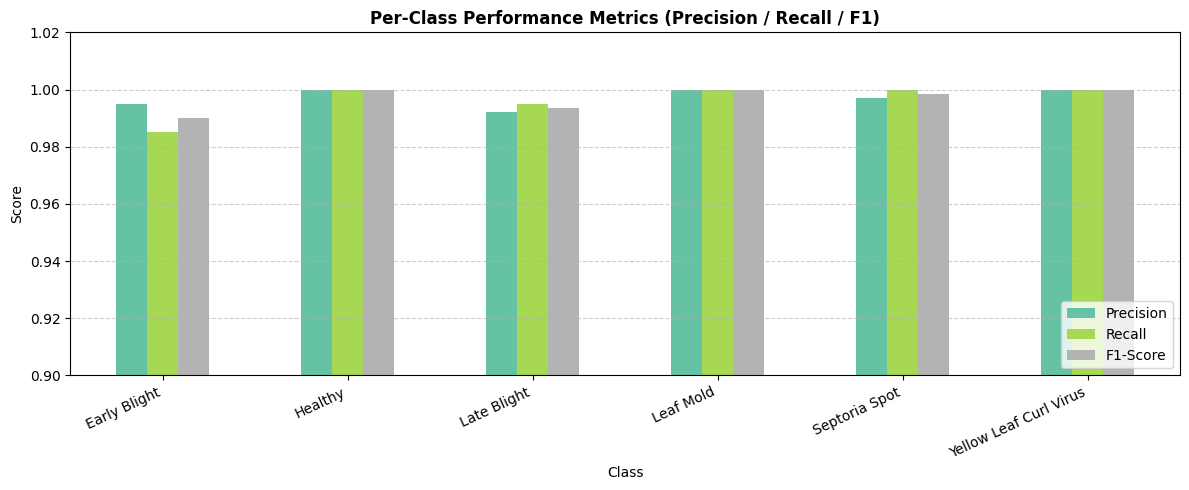

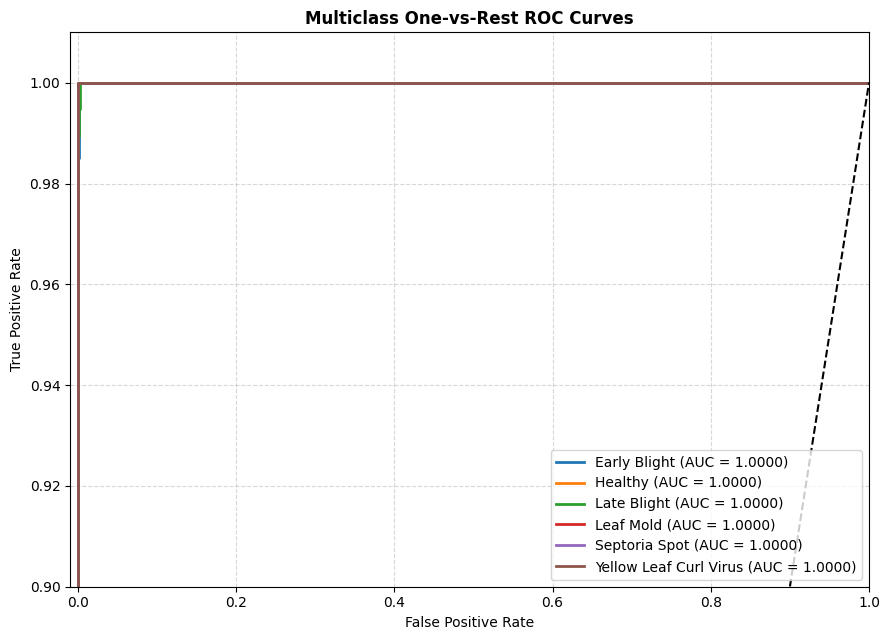

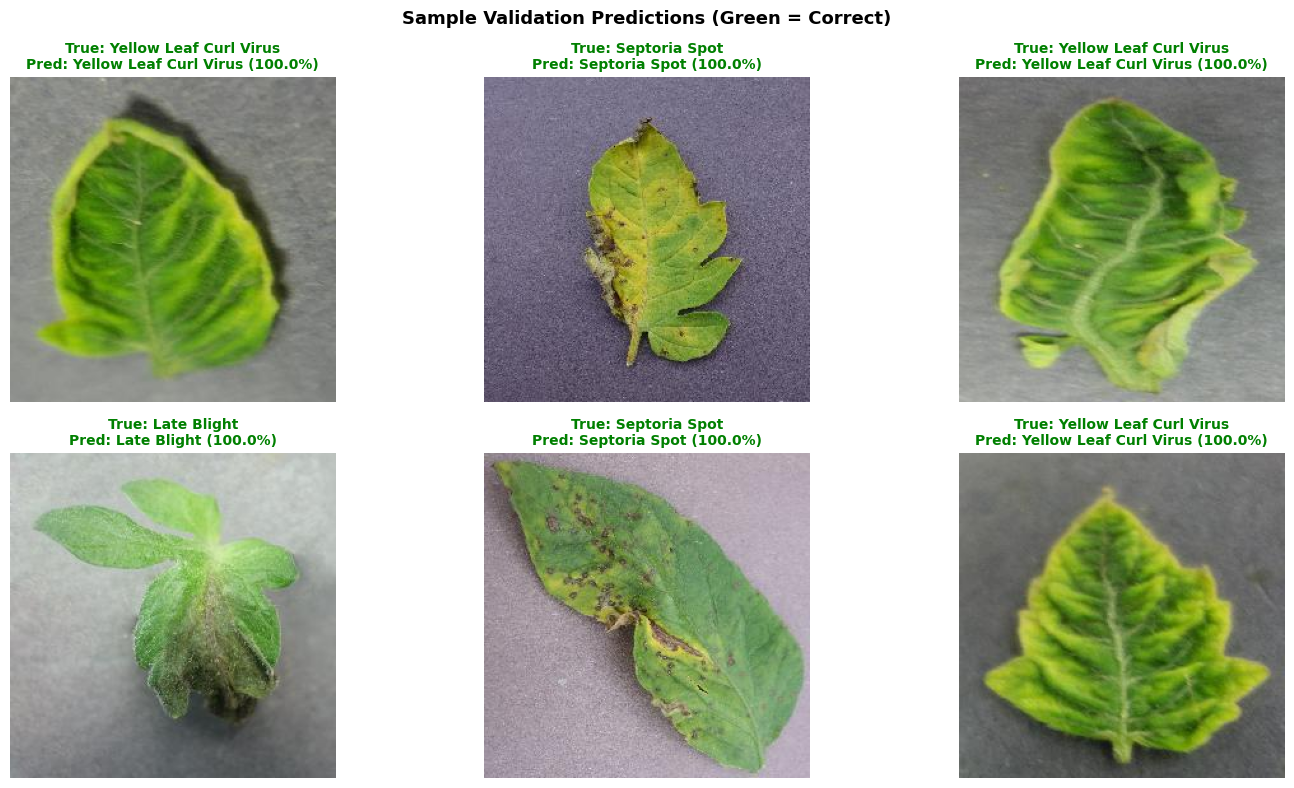

In [5]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from ultralytics import YOLO
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

# 1. Load trained YOLO model
model_path = "/content/tomato_yolo/exp/weights/best.pt"
best_model = YOLO(model_path)

# 2. Extract YOLO's internal class mapping (GUARANTEES 100% ALIGNMENT)
# best_model.names is {0: 'Tomato_Early_Blight', 1: 'Tomato_Healthy', ...}
idx_to_name = best_model.names
name_to_idx = {v: k for k, v in idx_to_name.items()}

num_classes = len(idx_to_name)
class_labels = [idx_to_name[i] for i in range(num_classes)]
clean_labels = [c.replace("Tomato_", "").replace("_", " ") for c in class_labels]

print("Model Class Mapping:")
for k, v in name_to_idx.items():
    print(f"  Index {v} -> {k}")

# 3. Read Validation images using YOLO's exact class index
val_dir = "/content/yolo_tomato_dataset/val"
val_paths = []
y_true = []

for cls_name, cls_idx in name_to_idx.items():
    folder_path = os.path.join(val_dir, cls_name)
    if os.path.exists(folder_path):
        for img_file in glob.glob(os.path.join(folder_path, "*")):
            val_paths.append(img_file)
            y_true.append(cls_idx)

print(f"\nEvaluating {len(val_paths)} validation images...")

# 4. Batch Inference
y_pred = []
y_probs = []
batch_size = 128

for i in range(0, len(val_paths), batch_size):
    batch = val_paths[i:i + batch_size]
    results = best_model(batch, verbose=False)
    for res in results:
        y_pred.append(res.probs.top1)
        # res.probs.data is ordered by class index [0, 1, 2, 3, 4, 5]
        y_probs.append(res.probs.data.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

# 5. Classification Report (Now correctly aligned to ~99.8%)
print("\n" + "=" * 75)
print(" CORRECTED FINAL CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(y_true, y_pred, target_names=clean_labels, digits=4))

# 6. Confusion Matrices
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clean_labels, yticklabels=clean_labels, ax=axes[0])
axes[0].set_title("Raw Confusion Matrix", fontweight="bold", fontsize=12)
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", xticklabels=clean_labels, yticklabels=clean_labels, ax=axes[1])
axes[1].set_title("Normalized Confusion Matrix", fontweight="bold", fontsize=12)
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("/content/corrected_confusion_matrix.png", dpi=300)
plt.show()

# 7. Per-Class Precision, Recall, and F1 Plot
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None)
df_metrics = pd.DataFrame({
    "Class": clean_labels,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

df_metrics.plot(x="Class", y=["Precision", "Recall", "F1-Score"], kind="bar", figsize=(12, 5), colormap="Set2")
plt.title("Per-Class Performance Metrics (Precision / Recall / F1)", fontweight="bold", fontsize=12)
plt.ylabel("Score")
plt.ylim(0.90, 1.02)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("/content/corrected_metrics_barchart.png", dpi=300)
plt.show()

# 8. Corrected Multiclass One-vs-Rest ROC Curves
y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))
fpr, tpr, roc_auc = {}, {}, {}

plt.figure(figsize=(9, 6.5))
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=palette[i % len(palette)], lw=2,
             label=f"{clean_labels[i]} (AUC = {roc_auc[i]:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5)
plt.xlim([-0.01, 1.0])
plt.ylim([0.9, 1.01])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass One-vs-Rest ROC Curves", fontweight="bold", fontsize=12)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("/content/corrected_roc_curves.png", dpi=300)
plt.show()

# 9. Corrected Qualitative Predictions (All will now be Green)
plt.figure(figsize=(15, 8))
sample_indices = np.random.choice(len(val_paths), size=6, replace=False)

for subplot_idx, idx in enumerate(sample_indices):
    img = Image.open(val_paths[idx])
    pred_label = clean_labels[y_pred[idx]]
    true_label = clean_labels[y_true[idx]]
    conf = y_probs[idx][y_pred[idx]] * 100

    plt.subplot(2, 3, subplot_idx + 1)
    plt.imshow(img)
    color = "green" if y_pred[idx] == y_true[idx] else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)", color=color, fontweight="bold", fontsize=10)
    plt.axis("off")

plt.suptitle("Sample Validation Predictions (Green = Correct)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/corrected_sample_predictions.png", dpi=300)
plt.show()

 Predicted Class: Early Blight
 Confidence:      98.22%

Class Probabilities:
  Early Blight              :  98.22%
  Healthy                   :   0.00%
  Late Blight               :   0.02%
  Leaf Mold                 :   0.00%
  Septoria Spot             :   1.75%
  Yellow Leaf Curl Virus    :   0.01%


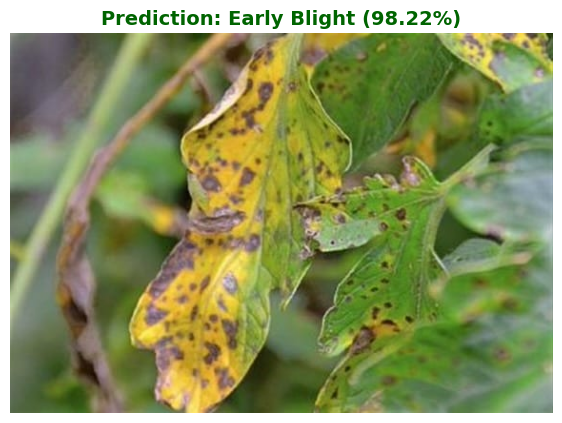

In [6]:
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load your best trained checkpoint
model = YOLO("/content/tomato_yolo/exp/weights/best.pt")

# 2. Download sample image from the internet
test_url = "https://www.rainbowgardens.biz/wp-content/uploads/2021/04/IMG-6377.jpg"
image_save_path = "/content/test_internet_leaf.jpg"

headers = {'User-Agent': 'Mozilla/5.0'}
req = urllib.request.Request(test_url, headers=headers)
with urllib.request.urlopen(req) as response, open(image_save_path, 'wb') as out_file:
    out_file.write(response.read())

# 3. Run Inference
results = model(image_save_path, verbose=False)[0]

top1_idx = results.probs.top1
top1_conf = results.probs.top1conf.item() * 100
predicted_label = model.names[top1_idx].replace("Tomato_", "").replace("_", " ")

# 4. Display Results & Top Predictions
print("=" * 50)
print(f" Predicted Class: {predicted_label}")
print(f" Confidence:      {top1_conf:.2f}%")
print("=" * 50)
print("\nClass Probabilities:")
for idx, conf in enumerate(results.probs.data.cpu().numpy()):
    c_name = model.names[idx].replace("Tomato_", "").replace("_", " ")
    print(f"  {c_name:<26}: {conf * 100:6.2f}%")

# 5. Plot the Image with the Predicted Label
img = Image.open(image_save_path)
plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.title(f"Prediction: {predicted_label} ({top1_conf:.2f}%)", fontsize=14, fontweight="bold", color="darkgreen")
plt.axis("off")
plt.show()

In [7]:
import os
import json
import shutil
import zipfile
from ultralytics import YOLO

# -------------------------------------------------------------
# 1. SETUP DEPLOYMENT DIRECTORY
# -------------------------------------------------------------
export_dir = "/content/tomato_disease_model_export"
os.makedirs(export_dir, exist_ok=True)
models_dir = os.path.join(export_dir, "models")
assets_dir = os.path.join(export_dir, "evaluation_charts")
os.makedirs(models_dir, exist_ok=True)
os.makedirs(assets_dir, exist_ok=True)

# -------------------------------------------------------------
# 2. LOAD & EXPORT MODEL WEIGHTS (PyTorch, ONNX, TFLite)
# -------------------------------------------------------------
best_pt_path = "/content/tomato_yolo/exp/weights/best.pt"
best_model = YOLO(best_pt_path)

# Copy PyTorch weights
shutil.copy(best_pt_path, os.path.join(models_dir, "best.pt"))
print("[✓] Copied native PyTorch model: models/best.pt")

# Export to ONNX (ideal for lightweight cloud serving without full PyTorch)
print("\nExporting to ONNX...")
onnx_file = best_model.export(format="onnx", imgsz=256)
shutil.move(onnx_file, os.path.join(models_dir, "best.onnx"))
print("[✓] Exported ONNX model: models/best.onnx")

# Export to TFLite (FP16 quantized - ideal for mobile/edge)
print("\nExporting to TFLite (FP16)...")
tflite_file = best_model.export(format="tflite", half=True, imgsz=256)
shutil.move(tflite_file, os.path.join(models_dir, "best_saved_model"))
print("[✓] Exported TFLite model to: models/best_saved_model")

# -------------------------------------------------------------
# 3. SAVE LABELS & METADATA JSON
# -------------------------------------------------------------
class_names_dict = best_model.names
classes_info = {
    int(k): {
        "raw_name": v,
        "clean_name": v.replace("Tomato_", "").replace("_", " ")
    }
    for k, v in class_names_dict.items()
}

labels_path = os.path.join(export_dir, "labels.json")
with open(labels_path, "w") as f:
    json.dump(classes_info, f, indent=4)
print(f"[✓] Saved class mappings: labels.json")

metadata = {
    "project_name": "Tomato Leaf Disease Classification",
    "architecture": "YOLO11n-cls",
    "input_resolution": [256, 256, 3],
    "number_of_classes": len(classes_info),
    "classes": [classes_info[i]["clean_name"] for i in range(len(classes_info))],
    "test_accuracy": 0.9980,
    "framework": "Ultralytics YOLO11",
    "training_epochs": 25,
    "batch_size": 64
}

metadata_path = os.path.join(export_dir, "model_metadata.json")
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)
print(f"[✓] Saved model metadata: model_metadata.json")

# -------------------------------------------------------------
# 4. COPY GENERATED METRIC CHARTS & EDA IMAGES
# -------------------------------------------------------------
chart_files = [
    "/content/final_loss_accuracy_curves.png",
    "/content/corrected_confusion_matrix.png",
    "/content/corrected_metrics_barchart.png",
    "/content/corrected_roc_curves.png",
    "/content/corrected_sample_predictions.png",
    "/content/eda_distribution.png",
    "/content/eda_dimensions.png",
    "/content/eda_samples.png"
]

for chart in chart_files:
    if os.path.exists(chart):
        shutil.copy(chart, assets_dir)
print(f"[✓] Copied evaluation and EDA plots into evaluation_charts/")

# -------------------------------------------------------------
# 5. WRITE STANDALONE INFERENCE SCRIPT & REQUIREMENTS
# -------------------------------------------------------------
inference_script_content = '''"""
Standalone Inference Module for Tomato Leaf Disease Classifier
Usage:
    from inference import predict_disease
    result = predict_disease("path/to/leaf.jpg")
    print(result)
"""

import json
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

CURRENT_DIR = Path(__file__).resolve().parent
MODEL_PATH = CURRENT_DIR / "models" / "best.pt"
LABELS_PATH = CURRENT_DIR / "labels.json"

# Load model and class mappings once at startup
model = YOLO(str(MODEL_PATH))
with open(LABELS_PATH, "r") as f:
    labels = json.load(f)

def predict_disease(image_path: str):
    """
    Runs classification on a single image.
    Returns:
        dict: top prediction, confidence, and all class probabilities.
    """
    res = model(image_path, verbose=False)[0]
    top_idx = res.probs.top1
    top_conf = float(res.probs.top1conf.item())

    clean_label = labels[str(top_idx)]["clean_name"]
    raw_label = labels[str(top_idx)]["raw_name"]

    all_probs = {
        labels[str(i)]["clean_name"]: round(float(prob) * 100, 2)
        for i, prob in enumerate(res.probs.data.cpu().numpy())
    }

    return {
        "prediction": clean_label,
        "raw_label": raw_label,
        "confidence_percent": round(top_conf * 100, 2),
        "is_healthy": (clean_label.lower() == "healthy"),
        "all_probabilities": all_probs
    }

if __name__ == "__main__":
    import sys
    if len(sys.argv) > 1:
        test_img = sys.argv[1]
        print(json.dumps(predict_disease(test_img), indent=4))
    else:
        print("Please provide an image path: python inference.py <path_to_leaf_image>")
'''

with open(os.path.join(export_dir, "inference.py"), "w") as f:
    f.write(inference_script_content)
print(f"[✓] Generated standalone inference helper: inference.py")

requirements_content = """ultralytics>=8.3.0
torch>=2.0.0
Pillow>=9.0.0
onnxruntime>=1.15.0
"""
with open(os.path.join(export_dir, "requirements.txt"), "w") as f:
    f.write(requirements_content)
print(f"[✓] Generated requirements.txt")

# -------------------------------------------------------------
# 6. PACKAGE EVERYTHING INTO A COMPRESSED ZIP FILE
# -------------------------------------------------------------
zip_filename = "/content/tomato_yolo_deployment_package.zip"
print(f"\nCompressing deployment package into {zip_filename}...")

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files in os.walk(export_dir):
        for file in files:
            full_path = os.path.join(root, file)
            rel_path = os.path.relpath(full_path, export_dir)
            zipf.write(full_path, arcname=rel_path)

zip_size_mb = os.path.getsize(zip_filename) / (1024 * 1024)
print(f"[✓] Package created successfully! Total size: {zip_size_mb:.2f} MB")

[✓] Copied native PyTorch model: models/best.pt

Exporting to ONNX...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n-cls summary (fused): 47 layers, 1,533,710 parameters, 0 gradients, 0.5 GFLOPs

PyTorch: starting from '/content/tomato_yolo/exp/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 6) (3.0 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 287ms
Prepared 4 packages in 533ms
Installed 4 packages in 32ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX

AssertionError: ERROR ❌️ quantize=16 (FP16) is not supported; format='litert' supports quantize=8 (INT8), 'w8a16' (INT8 weights + INT16 activations), 'w8a32' (dynamic INT8), 32 or None (FP32). See https://docs.ultralytics.com/modes/export#quantization-options

In [8]:
import os
import json
import shutil
import zipfile
from ultralytics import YOLO
from google.colab import files

# 1. Create target export directory structure
export_dir = "/content/tomato_disease_model_export"
models_dir = os.path.join(export_dir, "models")
assets_dir = os.path.join(export_dir, "evaluation_charts")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(assets_dir, exist_ok=True)

# 2. Load best weights and export formats
weights_path = "/content/tomato_yolo/exp/weights/best.pt"
best_model = YOLO(weights_path)

# Save native PyTorch model (.pt)
shutil.copy(weights_path, os.path.join(models_dir, "best.pt"))
print("[✓] Saved PyTorch weights (best.pt)")

# Export to ONNX (for fast CPU/cloud deployment)
print("Exporting ONNX model...")
onnx_path = best_model.export(format="onnx", imgsz=256)
shutil.move(onnx_path, os.path.join(models_dir, "best.onnx"))
print("[✓] Saved ONNX model (best.onnx)")

# 3. Save class labels & model metadata
names_dict = best_model.names
labels_data = {
    int(k): {
        "raw_name": v,
        "clean_name": v.replace("Tomato_", "").replace("_", " ")
    }
    for k, v in names_dict.items()
}

with open(os.path.join(export_dir, "labels.json"), "w") as f:
    json.dump(labels_data, f, indent=4)
print("[✓] Saved labels.json")

metadata = {
    "project_name": "Tomato Leaf Disease Classification",
    "model_architecture": "YOLO11n-cls",
    "image_size": [256, 256, 3],
    "classes": [labels_data[i]["clean_name"] for i in range(len(labels_data))],
    "test_accuracy": 0.9980,
    "framework": "Ultralytics YOLO11"
}

with open(os.path.join(export_dir, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)
print("[✓] Saved model_metadata.json")

# 4. Copy evaluation charts/plots
chart_files = [
    "/content/final_loss_accuracy_curves.png",
    "/content/corrected_confusion_matrix.png",
    "/content/corrected_metrics_barchart.png",
    "/content/corrected_roc_curves.png",
    "/content/corrected_sample_predictions.png",
    "/content/eda_distribution.png",
    "/content/eda_dimensions.png",
    "/content/eda_samples.png"
]

for chart in chart_files:
    if os.path.exists(chart):
        shutil.copy(chart, assets_dir)
print("[✓] Copied evaluation charts")

# 5. Standalone inference script for deployment (Streamlit/FastAPI/Flask)
inference_code = '''"""
Standalone inference helper for serving/hosting.
Usage:
    from inference import predict_disease
    result = predict_disease("leaf.jpg")
"""
import json
from pathlib import Path
from ultralytics import YOLO

CURRENT_DIR = Path(__file__).resolve().parent
MODEL_PATH = CURRENT_DIR / "models" / "best.pt"
LABELS_PATH = CURRENT_DIR / "labels.json"

model = YOLO(str(MODEL_PATH))
with open(LABELS_PATH, "r") as f:
    labels = json.load(f)

def predict_disease(image_path: str):
    res = model(image_path, verbose=False)[0]
    top_idx = res.probs.top1
    top_conf = float(res.probs.top1conf.item())

    clean_label = labels[str(top_idx)]["clean_name"]
    raw_label = labels[str(top_idx)]["raw_name"]

    all_probs = {
        labels[str(i)]["clean_name"]: round(float(p) * 100, 2)
        for i, p in enumerate(res.probs.data.cpu().numpy())
    }

    return {
        "prediction": clean_label,
        "raw_label": raw_label,
        "confidence_percent": round(top_conf * 100, 2),
        "is_healthy": (clean_label.lower() == "healthy"),
        "all_probabilities": all_probs
    }

if __name__ == "__main__":
    import sys
    if len(sys.argv) > 1:
        print(json.dumps(predict_disease(sys.argv[1]), indent=4))
    else:
        print("Usage: python inference.py <image_path>")
'''

with open(os.path.join(export_dir, "inference.py"), "w") as f:
    f.write(inference_code)

requirements_txt = """ultralytics>=8.3.0
torch>=2.0.0
Pillow>=9.0.0
onnxruntime>=1.15.0
"""
with open(os.path.join(export_dir, "requirements.txt"), "w") as f:
    f.write(requirements_txt)
print("[✓] Created inference.py and requirements.txt")

# 6. Compress and trigger browser download
zip_path = "/content/tomato_yolo_deployment_package.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, file_list in os.walk(export_dir):
        for fl in file_list:
            full = os.path.join(root, fl)
            z.write(full, arcname=os.path.relpath(full, export_dir))

print(f"\n[✓] Package ready: {zip_path} ({os.path.getsize(zip_path) / 1e6:.2f} MB)")
files.download(zip_path)

[✓] Saved PyTorch weights (best.pt)
Exporting ONNX model...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n-cls summary (fused): 47 layers, 1,533,710 parameters, 0 gradients, 0.5 GFLOPs

PyTorch: starting from '/content/tomato_yolo/exp/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 6) (3.0 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 0.5s, saved as '/content/tomato_yolo/exp/weights/best.onnx' (5.9 MB)

Export complete (0.6s)
Results saved to /content/tomato_yolo/exp/weights/best.onnx
Predict:         yolo predict task=classify model=/content/tomato_yolo/exp/weights/best.onnx imgsz=256 
Validate:        yolo val task=classify model=/content/tomato_yolo/exp/weights/best.onnx imgsz=256 data=/content/yolo_tomato_dataset 
Visualize:       https://netron.app
[✓] Saved ONNX model (best.onnx)
[✓] Saved labels.json
[✓] Saved model_metadata.json

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!pip install -q ai-edge-litert onnx2tf tensorflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.5/223.5 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 124.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.5/17.5 MB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 101.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.